# Módszertani kiegészítések és robusztussági vizsgálatok

Ez a notebook a 03. (gépi tanulás) notebook **után** futtatandó. Nem módosítja a végleges modellt:
a 03. notebook specifikációja (Ridge, alpha = 3, 14 változó, szint-célváltozó) a dolgozat *előre rögzített* végső modellje marad.
Az itt szereplő elemzések kiegészítések, és a dolgozatban is így kell jelölni őket.

Bemenet: `processed/KSH_Panel_FINAL_2018_2025.csv` és `results/machine_learning/KSH_ML_feature_matrix.csv` (a 03. notebook 23. cellája menti).

| Rész | Kérdés | Hova kerül a dolgozatban |
|---|---|---|
| A | Szint- vagy növekedési célváltozóval jobbak-e a modellek? Az Elastic Net rács rendben volt-e? | 3.6.2, 4.4.1 |
| B | Megveri-e a Ridge az erős, egyszerű referenciamodelleket (szezonális naiv driftel, ETS)? | 3.7.1, 4.5.1, Összegzés |
| C | Mekkora és milyen irányú a torzítás (bias) a fejlesztési és a tesztidőszakban? | 4.5.4 |
| D | Utólagos diagnosztika: tanulóablak-hossz | 4.5.4 / Korlátok |
| E | Mit mutat a panel a 2021/22-es forrásváltás környékén? | 3.2, 4.2.2 |
| F | Mennyire robusztus a klaszterezés? | 4.3 |
| G | Mennyire robusztus a területi együttmozgás? | 4.2.5–4.2.6 |

In [3]:
# CSOMAGOK ÉS FÁJLÚTVONALAK
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter
from scipy import stats

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Ridge, Lasso, ElasticNet, LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import ParameterGrid
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from statsmodels.tsa.holtwinters import ExponentialSmoothing   # pip install statsmodels

BASE_DIR = Path.cwd()
PROCESSED = BASE_DIR / "processed"
ML_RESULTS = BASE_DIR / "results" / "machine_learning"
ML_FIGURES = BASE_DIR / "figures" / "machine_learning"
FIGURES = BASE_DIR / "figures"
for folder in (ML_RESULTS, ML_FIGURES, FIGURES):
    folder.mkdir(parents=True, exist_ok=True)

PANEL_FILE = PROCESSED / "KSH_Panel_FINAL_2018_2025.csv"
FEATURE_FILE = ML_RESULTS / "KSH_ML_feature_matrix.csv"
for file in (PANEL_FILE, FEATURE_FILE):
    if not file.exists():
        raise FileNotFoundError(f"Hiányzó fájl: {file}")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 7)
huf = FuncFormatter(lambda v, p: f"{v:,.0f}".replace(",", " "))
AREA = "Területi egység neve"

In [5]:
# ADATOK BETÖLTÉSE ÉS ELLENŐRZÉSE
df_panel = pd.read_csv(PANEL_FILE, encoding="utf-8-sig", parse_dates=["Dátum", "Cél_Dátum"])
df_panel = df_panel.sort_values(["Dátum", AREA]).reset_index(drop=True)
df_model = pd.read_csv(FEATURE_FILE, encoding="utf-8-sig", parse_dates=["Dátum", "Cél_Dátum"])
df_model = df_model.sort_values(["Cél_Dátum", AREA]).reset_index(drop=True)

assert df_panel.shape == (640, 15)
assert len(df_model) == 540 and df_model["Cél_Dátum"].nunique() == 27

# A 03. notebookkal azonos változócsoportok (időtrend nélkül: 14 változó)
wage_features = ["Bruttó_átlagkereset_HUF", "Bér_Lag1", "Bér_Lag2", "Bér_Lag3", "Bér_Lag4",
                 "Bér_Növekedés_QoQ", "Bér_Növekedés_YoY"]
labour_features = ["Munkanélküliségi_ráta_%", "Munkanélküliség_Lag1", "Munkanélküliség_Lag4",
                   "Munkanélküliség_Delta", "Álláskeresők_1000_foglalkoztatottra"]
NUM = wage_features + labour_features
CAT = [AREA, "Negyedév_kategória"]
TARGET = "Jövő_Negyedévi_Bér"
assert len(NUM + CAT) == 14

DEV_START, DEV_END = pd.Timestamp("2021-01-01"), pd.Timestamp("2023-10-01")
TEST_START, TEST_END = pd.Timestamp("2024-01-01"), pd.Timestamp("2025-10-01")
dev_dates = [pd.Timestamp(x) for x in sorted(df_model.loc[df_model["Cél_Dátum"].between(DEV_START, DEV_END), "Cél_Dátum"].unique())]
test_dates = [pd.Timestamp(x) for x in sorted(df_model.loc[df_model["Cél_Dátum"].between(TEST_START, TEST_END), "Cél_Dátum"].unique())]
assert len(dev_dates) == 12 and len(test_dates) == 8
print("Adatok rendben:", df_model.shape, "| fejlesztési negyedévek:", len(dev_dates), "| tesztnegyedévek:", len(test_dates))

Adatok rendben: (540, 27) | fejlesztési negyedévek: 12 | tesztnegyedévek: 8


In [6]:
# KÖZÖS FÜGGVÉNYEK
def make_pipeline(estimator, numeric, categorical):
    steps = []
    if numeric:
        steps.append(("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), numeric))
    if categorical:
        steps.append(("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                                       ("oh", OneHotEncoder(handle_unknown="ignore", drop="first", sparse_output=False))]), categorical))
    return Pipeline([("pre", ColumnTransformer(steps, remainder="drop")), ("model", clone(estimator))])


def walk_forward(data, dates, estimator, name, numeric=NUM, categorical=CAT, target="szint", window=None):
    """Egy negyedéves előrejelzés, minden lépésben újratanítva (az előfeldolgozás is).
    target: 'szint'  -> W(t+1)                     (a dolgozat jelenlegi célváltozója)
            'qoq'    -> ln(W(t+1)/W(t))            (negyedéves növekedés)
            'yoy'    -> ln(W(t+1)/W(t-3))          (az előző év azonos negyedévéhez viszonyított változás)
    window: None = expanding window; egész szám = sliding window (negyedévek száma, mint a 03. notebookban)"""
    frames = []
    for d in dates:
        past = sorted(data.loc[data["Cél_Dátum"] < d, "Cél_Dátum"].unique())
        start = past[-window] if (window and len(past) > window) else past[0]
        train = data[(data["Cél_Dátum"] >= start) & (data["Cél_Dátum"] < d)]
        test = data[data["Cél_Dátum"] == d]
        assert len(test) == 20 and train["Cél_Dátum"].max() < d          # nincs szivárgás
        y = train[TARGET].to_numpy()
        if target == "szint":
            y_fit = y
        elif target == "qoq":
            y_fit = np.log(y / train["Bruttó_átlagkereset_HUF"].to_numpy())
        elif target == "yoy":
            y_fit = np.log(y / train["Bér_Lag3"].to_numpy())
        else:
            raise ValueError(target)
        model = make_pipeline(estimator, numeric, categorical).fit(train[numeric + categorical], y_fit)
        p = model.predict(test[numeric + categorical])
        if target == "qoq":
            p = test["Bruttó_átlagkereset_HUF"].to_numpy() * np.exp(p)
        elif target == "yoy":
            p = test["Bér_Lag3"].to_numpy() * np.exp(p)
        out = test[["Dátum", "Cél_Dátum", AREA]].copy()
        out["Modell"] = name
        out["Valós_bér"] = test[TARGET].to_numpy()
        out["Predikció"] = p
        out["Hiba"] = out["Predikció"] - out["Valós_bér"]
        out["Abszolút_hiba"] = out["Hiba"].abs()
        frames.append(out)
    return pd.concat(frames, ignore_index=True)


def quarterly_mae(pred):
    return pred.groupby("Cél_Dátum")["Abszolút_hiba"].mean()


def summarize(pred):
    y, e = pred["Valós_bér"], pred["Hiba"]
    return {"Átlag_MAE": quarterly_mae(pred).mean(),
            "RMSE_pooled": float(np.sqrt((e ** 2).mean())),
            "MAPE_%": float((e.abs() / y).mean() * 100),
            "Bias": float(e.mean()),
            "Felülbecslés_%": float((e > 0).mean() * 100),
            "R2_pooled": float(1 - (e ** 2).sum() / ((y - y.mean()) ** 2).sum())}


def hln_test(mae_reference, mae_ridge):
    """Páros teszt a negyedéves MAE-különbségekre (Diebold–Mariano, h=1, Harvey–Leybourne–Newbold-korrekcióval).
    Pozitív átlagkülönbség = a Ridge jobb. Kis mintán (8–20 negyedév) csak tájékoztató jellegű."""
    d = (mae_reference - mae_ridge).dropna()
    n = len(d)
    t = d.mean() / (d.std(ddof=1) / np.sqrt(n)) * np.sqrt((n - 1) / n)
    p = 2 * (1 - stats.t.cdf(abs(t), df=n - 1))
    w = stats.wilcoxon(d).pvalue
    return {"Átlagkülönbség_Ft (ref − Ridge)": d.mean(), "t_HLN": t, "p_HLN": p, "p_Wilcoxon": w,
            "Ridge_jobb_negyedévek": f"{int((d > 0).sum())}/{n}"}


# ELLENŐRZÉS: a dolgozat számainak reprodukciója
_dev = summarize(walk_forward(df_model, dev_dates, Ridge(alpha=3), "ellenőrzés"))
_test = summarize(walk_forward(df_model, test_dates, Ridge(alpha=3), "ellenőrzés"))
print(f"Fejlesztési MAE: {_dev['Átlag_MAE']:,.0f} Ft (a dolgozatban 8 940)")
print(f"Végső teszt MAE: {_test['Átlag_MAE']:,.0f} Ft (a dolgozatban 10 002) | bias {_test['Bias']:+,.0f} Ft (+8 101) | R2 {_test['R2_pooled']:.3f} (0,973)")
if abs(_dev["Átlag_MAE"] - 8940) > 5 or abs(_test["Átlag_MAE"] - 10002) > 5:
    warnings.warn("A reprodukció nem egyezik a dolgozat számaival, ellenőrizd a feature-mátrixot!")

Fejlesztési MAE: 8,940 Ft (a dolgozatban 8 940)
Végső teszt MAE: 10,002 Ft (a dolgozatban 10 002) | bias +8,101 Ft (+8 101) | R2 0.973 (0,973)


## A. Szint- vagy növekedési célváltozó? Az Elastic Net rács ellenőrzése

**Miért:** a bér 296 ezerről 704 ezer Ft-ra nő. A faalapú modellek nem extrapolálnak jól a tanulóadatok tartományán kívül (ezt a 2.6.3-ban te is leírod), ezért szintre becsülve eleve hátrányban vannak.
A növekedési célváltozónál (a negyedéves változás logaritmusa) ugyanazt a keretet használjuk, az előrejelzést visszaszorozzuk forintra, így a hiba forintban továbbra is összevethető.

**Fegyelem:** minden modell- és paraméterválasztás kizárólag a 2021–2023-as fejlesztési szakaszon történik. A teszt itt nem szerepel.

In [7]:
# A.1 PARAMÉTERRÁCSOK
# 'szint': a dolgozat (03. notebook) rácsai. Az Elastic Net itt két változatban: eredeti és bővített rács.
# 'qoq' / 'yoy': a Lasso/Elastic Net célváltozója ~0,03 nagyságrendű, ezért az alfa-rács más skálán van.
common_trees = {
    "Random Forest": (RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
                      {"max_depth": [4, None], "min_samples_leaf": [2, 5], "max_features": [0.7, 1.0]}),
    "Gradient Boosting": (GradientBoostingRegressor(random_state=42, min_samples_leaf=3),
                          {"n_estimators": [100, 200], "learning_rate": [0.03, 0.05], "max_depth": [2, 3]}),
}
grids = {
    "szint": {
        "Lineáris regresszió": (LinearRegression(), {}),
        "Ridge": (Ridge(), {"alpha": [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100, 300]}),
        "Lasso": (Lasso(max_iter=100000, tol=1e-4), {"alpha": [10, 30, 100, 300, 1000, 3000]}),
        "Elastic Net (eredeti rács)": (ElasticNet(max_iter=100000, tol=1e-4), {"alpha": [10, 100, 300, 1000], "l1_ratio": [0.1, 0.5, 0.9]}),
        "Elastic Net (bővített rács)": (ElasticNet(max_iter=100000, tol=1e-4),
                                        {"alpha": [0.1, 1, 10, 30, 100, 300, 1000], "l1_ratio": [0.1, 0.5, 0.9, 1.0]}),
    },
    "növekedés": {
        "Lineáris regresszió": (LinearRegression(), {}),
        "Ridge": (Ridge(), {"alpha": [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100, 300]}),
        "Lasso": (Lasso(max_iter=100000, tol=1e-6), {"alpha": list(np.logspace(-6, -2, 9))}),
        "Elastic Net (bővített rács)": (ElasticNet(max_iter=100000, tol=1e-6),
                                        {"alpha": list(np.logspace(-5, -2, 7)), "l1_ratio": [0.1, 0.5, 0.9, 1.0]}),
    },
}
for tgt in grids.values():
    tgt.update(common_trees)
target_code = {"szint": "szint", "növekedés": "qoq"}      # 'yoy' változat lent, külön cellában

# A.2 FUTTATÁS (kb. 3–4 perc)
rows = []
for target_name, family_dict in grids.items():
    for family, (estimator, grid) in family_dict.items():
        best = None
        for params in ParameterGrid(grid):
            pred = walk_forward(df_model, dev_dates, clone(estimator).set_params(**params),
                                f"{family}", target=target_code[target_name])
            s = summarize(pred)
            if best is None or s["Átlag_MAE"] < best[0]["Átlag_MAE"]:
                best = (s, params)
        rows.append({"Célváltozó": target_name, "Modell": family, "Legjobb paraméterek": {k: (round(float(v), 8) if isinstance(v, (float, np.floating)) else v) for k, v in best[1].items()},
                     "Fejlesztési MAE (Ft)": best[0]["Átlag_MAE"], "Bias (Ft)": best[0]["Bias"]})
        print(f"{target_name:10s} {family:30s} MAE = {best[0]['Átlag_MAE']:9,.0f}  bias = {best[0]['Bias']:9,.0f}")
target_comparison = pd.DataFrame(rows)

szint      Lineáris regresszió            MAE =     9,884  bias =    -4,186
szint      Ridge                          MAE =     8,940  bias =    -5,320
szint      Lasso                          MAE =     9,392  bias =    -5,725
szint      Elastic Net (eredeti rács)     MAE =    21,372  bias =   -21,013
szint      Elastic Net (bővített rács)    MAE =     9,001  bias =    -5,375
szint      Random Forest                  MAE =    12,327  bias =    -8,616
szint      Gradient Boosting              MAE =    12,133  bias =    -8,913
növekedés  Lineáris regresszió            MAE =     9,093  bias =    -3,531
növekedés  Ridge                          MAE =     8,368  bias =    -4,129
növekedés  Lasso                          MAE =     8,170  bias =    -4,365
növekedés  Elastic Net (bővített rács)    MAE =     8,145  bias =    -4,397
növekedés  Random Forest                  MAE =     9,157  bias =    -2,821
növekedés  Gradient Boosting              MAE =     9,700  bias =    -4,100


Célváltozó,növekedés,szint,Változás szint → növekedés (%)
Modell,,,
Elastic Net (bővített rács),8144.8,9001.4,-9.5
Lasso,8170.5,9392.0,-13.0
Ridge,8368.5,8939.8,-6.4
Lineáris regresszió,9093.3,9884.5,-8.0
Random Forest,9156.6,12326.8,-25.7
Gradient Boosting,9699.7,12132.7,-20.1
Elastic Net (eredeti rács),NaN,21371.7,NaN


szint      Random Forest     :   12,327 Ft, a legjobb lineáris modellnél +38%-kal rosszabb
szint      Gradient Boosting :   12,133 Ft, a legjobb lineáris modellnél +36%-kal rosszabb
növekedés  Random Forest     :    9,157 Ft, a legjobb lineáris modellnél +12%-kal rosszabb
növekedés  Gradient Boosting :    9,700 Ft, a legjobb lineáris modellnél +19%-kal rosszabb


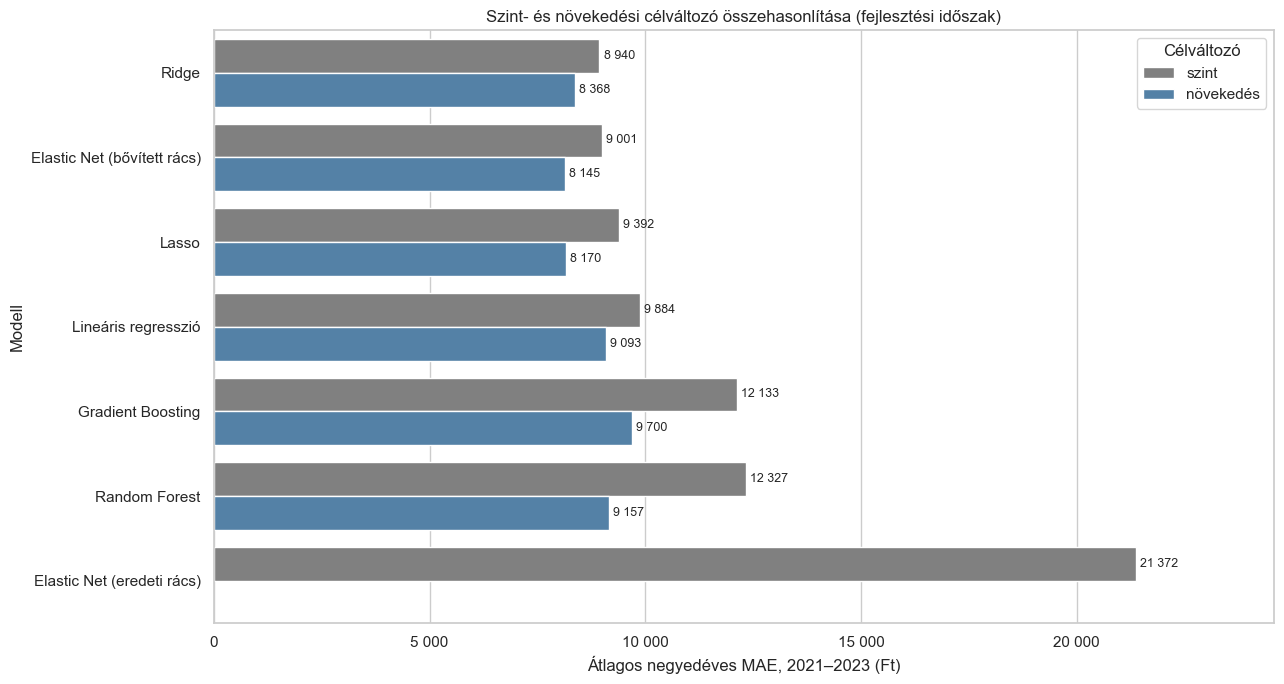

In [8]:
# A.3 ÖSSZEFOGLALÓ TÁBLA ÉS ÁBRA
pivot = target_comparison.pivot(index="Modell", columns="Célváltozó", values="Fejlesztési MAE (Ft)")
pivot["Változás szint → növekedés (%)"] = (pivot["növekedés"] / pivot["szint"] - 1) * 100
display(pivot.round(1).sort_values("növekedés"))

best_linear = {t: target_comparison[(target_comparison["Célváltozó"] == t) &
                                    (target_comparison["Modell"].isin(["Ridge", "Lasso", "Elastic Net (bővített rács)", "Lineáris regresszió"]))]["Fejlesztési MAE (Ft)"].min()
               for t in ["szint", "növekedés"]}
for t in ["szint", "növekedés"]:
    for tree in ["Random Forest", "Gradient Boosting"]:
        v = float(pivot.loc[tree, t])
        print(f"{t:10s} {tree:18s}: {v:8,.0f} Ft, a legjobb lineáris modellnél {100 * (v / best_linear[t] - 1):+.0f}%-kal rosszabb")

plot_data = target_comparison.copy()
order = pivot.sort_values("szint").index.tolist()
fig, ax = plt.subplots(figsize=(13, 7))
sns.barplot(data=plot_data, y="Modell", x="Fejlesztési MAE (Ft)", hue="Célváltozó", order=order,
            palette={"szint": "grey", "növekedés": "steelblue"}, ax=ax)
for container in ax.containers:
    ax.bar_label(container, labels=[f"{v:,.0f}".replace(",", " ") for v in container.datavalues], padding=3, fontsize=9)
ax.xaxis.set_major_formatter(huf)
ax.set_xlim(0, plot_data["Fejlesztési MAE (Ft)"].max() * 1.15)
ax.set_xlabel("Átlagos negyedéves MAE, 2021–2023 (Ft)")
ax.set_title("Szint- és növekedési célváltozó összehasonlítása (fejlesztési időszak)")
plt.tight_layout()
fig.savefig(ML_FIGURES / "celvaltozo_osszehasonlitas_fejlesztes.png", dpi=300, bbox_inches="tight")
plt.show()
target_comparison.to_csv(ML_RESULTS / "KSH_rob_celvaltozo_osszehasonlitas.csv", index=False, encoding="utf-8-sig")

**Mit olvass ki belőle?**
- Az **Elastic Net** eredeti rácsán minden konfiguráció rossz, mert az alfa-tartomány 10-nél indul. Bővített rácson az Elastic Net a Ridge/Lasso szintjére kerül. A dolgozatban szereplő „17 318 Ft” rács-műtermék, nem modellkülönbség.
- A **fák** növekedési célváltozóval sokat javulnak, így a „lineáris > fa” különbség a szintes elrendezés egy része.
- A fejlesztési időszakban mindhárom regularizált lineáris modell közel azonos (a különbségek 12 negyedévnél zajszintűek). Ezért **nem javaslom a végleges modell cseréjét**: a végleges specifikáció a teszt előtt rögzített. A növekedési célváltozós változat érzékenységvizsgálatként szerepeljen.

## B. Erős referenciamodellek

A dolgozat két referenciája (előző negyedéves naiv, előző évi azonos negyedév) gyenge: az első nem ismeri a szezonalitást, a második 9–15%-os éves bérnövekedés mellett szükségszerűen sokat téved.
Két erősebb, **nem tanuló** vagy alig hangolt referencia:

1. **Szezonális naiv driftel:** a célnegyedév előző évi értéke szorozva az utolsó ismert éves növekedéssel: Ŵ(t+1) = W(t−3) · W(t)/W(t−4). Két változat: területi növekedéssel és a 20 terület közös (átlagos) növekedésével.
2. **ETS (Holt–Winters), területenként:** damped additív trend + szezonalitás. A specifikációt (additív/multiplikatív szezonalitás, trend/nincs) **a fejlesztési időszakon** választjuk, és csak a nyertest értékeljük a teszten.

**Átláthatóság:** ezeket a referenciákat a végső teszt eredményeinek ismeretében adtuk hozzá. A dolgozatban ezt ki kell mondani.

In [9]:
# B.1 REFERENCIAMODELLEK
def drift_reference(data, dates, mode):
    d = data[data["Cél_Dátum"].isin(dates)].copy()
    growth = d["Bruttó_átlagkereset_HUF"] / d["Bér_Lag4"]                  # éves növekedés az információs negyedévben
    if mode == "terület":
        p = d["Bér_Lag3"] * growth
    elif mode == "közös":
        p = d["Bér_Lag3"] * growth.groupby(d["Cél_Dátum"]).transform("mean")
    elif mode == "naiv":
        p = d["Bruttó_átlagkereset_HUF"]
    elif mode == "szezonális naiv":
        p = d["Bér_Lag3"]
    out = d[["Dátum", "Cél_Dátum", AREA]].copy()
    out["Valós_bér"] = d[TARGET].to_numpy()
    out["Predikció"] = p.to_numpy()
    out["Hiba"] = out["Predikció"] - out["Valós_bér"]
    out["Abszolút_hiba"] = out["Hiba"].abs()
    return out

wide = (df_panel.pivot(index="Dátum", columns=AREA, values="Bruttó_átlagkereset_HUF").sort_index())
ets_failures = {"n": 0}

def ets_reference(dates, seasonal, trend, damped):
    rows = []
    for tgt in dates:
        info = tgt - pd.DateOffset(months=3)
        for area in wide.columns:
            y = wide.loc[:info, area].to_numpy()                          # csak az információs negyedévig ismert adat
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter("always")
                fit = ExponentialSmoothing(y, trend=trend, damped_trend=bool(damped and trend), seasonal=seasonal,
                                           seasonal_periods=4, initialization_method="estimated").fit()
            ets_failures["n"] += int(any("converge" in str(w.message).lower() for w in caught))
            rows.append({"Dátum": info, "Cél_Dátum": tgt, AREA: area,
                         "Valós_bér": wide.loc[tgt, area], "Predikció": float(fit.forecast(1)[0])})
    out = pd.DataFrame(rows)
    out["Hiba"] = out["Predikció"] - out["Valós_bér"]
    out["Abszolút_hiba"] = out["Hiba"].abs()
    return out

# B.2 AZ ETS-SPECIFIKÁCIÓ KIVÁLASZTÁSA – KIZÁRÓLAG A FEJLESZTÉSI IDŐSZAKON
ets_candidates = {"ETS mul. szezon + damped trend": dict(seasonal="mul", trend="add", damped=True),
                  "ETS add. szezon + damped trend": dict(seasonal="add", trend="add", damped=True),
                  "ETS mul. szezon, trend nélkül": dict(seasonal="mul", trend=None, damped=False),
                  "ETS add. szezon, trend nélkül": dict(seasonal="add", trend=None, damped=False)}
ets_dev = {k: summarize(ets_reference(dev_dates, **v))["Átlag_MAE"] for k, v in ets_candidates.items()}
display(pd.Series(ets_dev, name="Fejlesztési MAE (Ft)").round(0).to_frame())
ets_choice = min(ets_dev, key=ets_dev.get)
print("Kiválasztott ETS-specifikáció (fejlesztési MAE alapján):", ets_choice)

,Fejlesztési MAE (Ft)
ETS mul. szezon + damped trend,9989.0
ETS add. szezon + damped trend,11376.0
"ETS mul. szezon, trend nélkül",17234.0
"ETS add. szezon, trend nélkül",16835.0


Kiválasztott ETS-specifikáció (fejlesztési MAE alapján): ETS mul. szezon + damped trend


In [10]:
# B.3 MINDEN MODELL A FEJLESZTÉSI ÉS A TESZTIDŐSZAKON
final_ridge_name = "Végleges Ridge (szint, α=3)"
models = {}
for period, dates in (("fejlesztés", dev_dates), ("teszt", test_dates)):
    models[(period, final_ridge_name)] = walk_forward(df_model, dates, Ridge(alpha=3), final_ridge_name)
    models[(period, "Ridge, növekedési cél (utólagos)")] = walk_forward(df_model, dates, Ridge(alpha=3), "Ridge qoq", target="qoq")
    models[(period, "Naiv – előző negyedév")] = drift_reference(df_model, dates, "naiv")
    models[(period, "Szezonális naiv – előző év")] = drift_reference(df_model, dates, "szezonális naiv")
    models[(period, "Szezonális naiv driftel (terület)")] = drift_reference(df_model, dates, "terület")
    models[(period, "Szezonális naiv driftel (közös)")] = drift_reference(df_model, dates, "közös")
    models[(period, "ETS (fejlesztésen választott)")] = ets_reference(dates, **ets_candidates[ets_choice])
print("ETS-illesztések, ahol az optimalizáló nem konvergált:", ets_failures["n"])

rows = []
for (period, name), pred in models.items():
    rows.append({"Időszak": period, "Modell": name, **summarize(pred)})
reference_summary = pd.DataFrame(rows)
table = reference_summary.pivot(index="Modell", columns="Időszak",
                                values=["Átlag_MAE", "Bias", "MAPE_%", "Felülbecslés_%", "R2_pooled"])
table = table.reindex(columns=[(m, p) for m in ["Átlag_MAE", "MAPE_%", "Bias", "Felülbecslés_%", "R2_pooled"] for p in ["fejlesztés", "teszt"]])

# 20 negyedév együtt (12 fejlesztési + 8 teszt)
q_all = {name: pd.concat([quarterly_mae(models[("fejlesztés", name)]), quarterly_mae(models[("teszt", name)])])
         for name in [n for (p, n) in models if p == "teszt"]}
table[("Átlag_MAE", "20 negyedév")] = pd.Series({k: v.mean() for k, v in q_all.items()})
order_models = ["Végleges Ridge (szint, α=3)", "Ridge, növekedési cél (utólagos)", "ETS (fejlesztésen választott)",
                "Szezonális naiv driftel (terület)", "Szezonális naiv driftel (közös)", "Naiv – előző negyedév", "Szezonális naiv – előző év"]
display(table.loc[order_models].round({("Átlag_MAE", "fejlesztés"): 0, ("Átlag_MAE", "teszt"): 0, ("Átlag_MAE", "20 negyedév"): 0,
                                      ("Bias", "fejlesztés"): 0, ("Bias", "teszt"): 0}).round(2))
reference_summary.to_csv(ML_RESULTS / "KSH_rob_referenciamodellek.csv", index=False, encoding="utf-8-sig")

ETS-illesztések, ahol az optimalizáló nem konvergált: 4


Átlag_MAE              MAPE_%         \
Időszak                           fejlesztés    teszt fejlesztés  teszt   
Modell                                                                    
Végleges Ridge (szint, α=3)           8940.0  10002.0       1.97   1.66   
Ridge, növekedési cél (utólagos)      8368.0  10660.0       1.86   1.76   
ETS (fejlesztésen választott)         9989.0   5914.0       2.24   1.00   
Szezonális naiv driftel (terület)    11329.0   6434.0       2.54   1.08   
Szezonális naiv driftel (közös)      10952.0   7395.0       2.43   1.21   
Naiv – előző negyedév                18800.0  22837.0       4.05   3.65   
Szezonális naiv – előző év           51105.0  60161.0      11.32  10.15   

                                        Bias          Felülbecslés_%         \
Időszak                           fejlesztés    teszt     fejlesztés  teszt   
Modell                                                                        
Végleges Ridge (szint, α=3)          -5320.0   8101.0          35.00  83.12   
Ridge, növekedési cél (utólagos)     -4129.0   9082.0          38.33  86.88   
ETS (fejlesztésen választott)        -3848.0   1616.0          32.92  54.37   
Szezonális naiv driftel (terület)    -1597.0   4112.0          45.83  71.88   
Szezonális naiv driftel (közös)      -1368.0   4500.0          44.58  68.75   
Naiv – előző negyedév               -14168.0 -14898.0          27.50  35.00   
Szezonális naiv – előző év          -51105.0 -60161.0           0.00   0.00   

                                   R2_pooled         Átlag_MAE  
Időszak                           fejlesztés teszt 20 negyedév  
Modell                                                          
Végleges Ridge (szint, α=3)             0.97  0.97      9365.0  
Ridge, növekedési cél (utólagos)        0.97  0.97      9285.0  
ETS (fejlesztésen választott)           0.96  0.99      8359.0  
Szezonális naiv driftel (terület)       0.96  0.99      9371.0  
Szezonális naiv driftel (közös)         0.96  0.99      9529.0  
Naiv – előző negyedév                   0.90  0.86     20415.0  
Szezonális naiv – előző év              0.54  0.42     54727.0

In [11]:
# B.4 PÁROS TESZTEK: a végleges Ridge vs. referenciamodellek (pozitív különbség = a Ridge jobb)
rows = []
for ref in ["ETS (fejlesztésen választott)", "Szezonális naiv driftel (terület)", "Szezonális naiv driftel (közös)", "Naiv – előző negyedév"]:
    for label, qa, qb in (("fejlesztés", quarterly_mae(models[("fejlesztés", ref)]), quarterly_mae(models[("fejlesztés", final_ridge_name)])),
                          ("teszt", quarterly_mae(models[("teszt", ref)]), quarterly_mae(models[("teszt", final_ridge_name)])),
                          ("20 negyedév", q_all[ref], q_all[final_ridge_name])):
        rows.append({"Referencia": ref, "Időszak": label, **hln_test(qa, qb)})
paired_tests = pd.DataFrame(rows)
display(paired_tests.round(3))
paired_tests.to_csv(ML_RESULTS / "KSH_rob_parositott_tesztek.csv", index=False, encoding="utf-8-sig")

,Referencia,Időszak,Átlagkülönbség_Ft (ref − Ridge),t_HLN,p_HLN,p_Wilcoxon,Ridge_jobb_negyedévek
0,ETS (fejlesztésen választott),fejlesztés,1049.604,0.589,0.568,0.970,6/12
1,ETS (fejlesztésen választott),teszt,-4087.998,-2.697,0.031,0.109,3/8
2,ETS (fejlesztésen választott),20 negyedév,-1005.437,-0.765,0.453,0.216,9/20
3,Szezonális naiv driftel (terület),fejlesztés,2388.745,1.213,0.251,0.301,8/12
4,Szezonális naiv driftel (terület),teszt,-3567.150,-2.180,0.066,0.109,2/8
5,Szezonális naiv driftel (terület),20 negyedév,6.387,0.004,0.997,0.898,10/20
6,Szezonális naiv driftel (közös),fejlesztés,2012.370,1.023,0.328,0.519,7/12
7,Szezonális naiv driftel (közös),teszt,-2607.072,-1.500,0.177,0.312,4/8
8,Szezonális naiv driftel (közös),20 negyedév,164.593,0.117,0.908,0.956,11/20
9,Naiv – előző negyedév,fejlesztés,9860.355,2.325,0.040,0.012,11/12


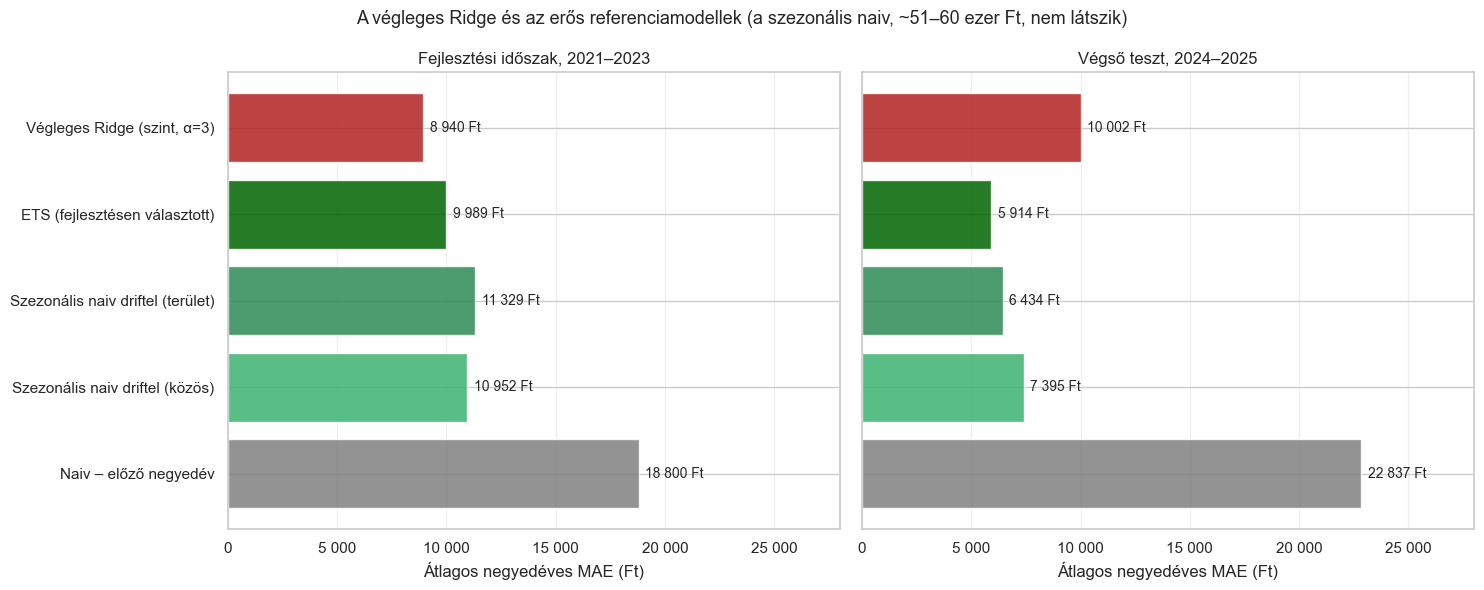

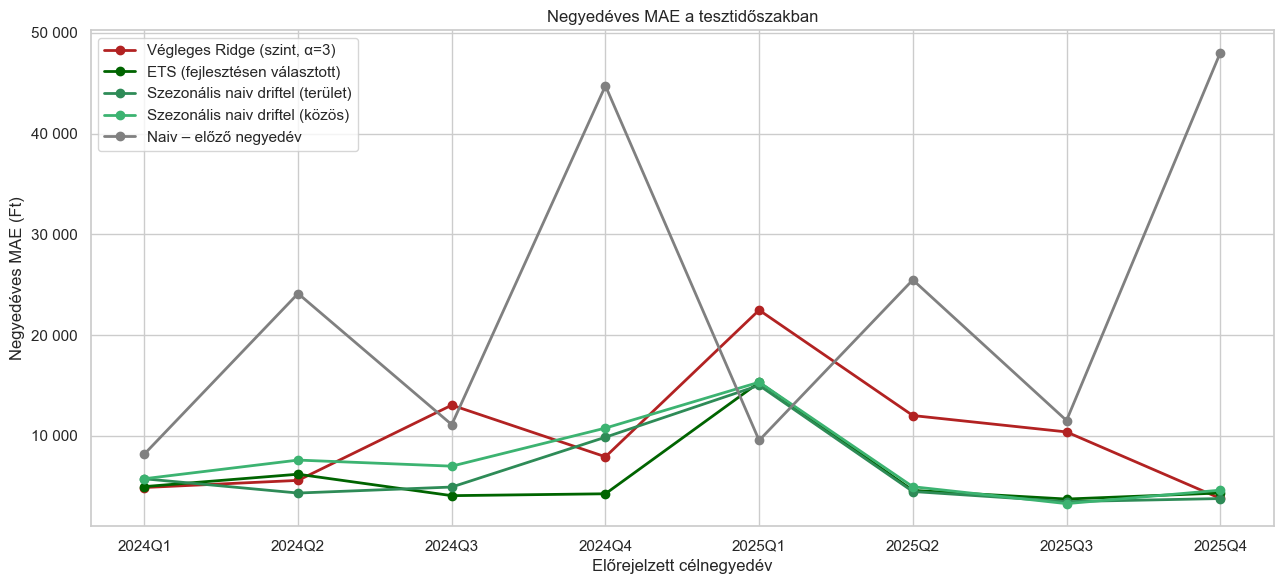

In [12]:
# B.5 ÁBRÁK
show = ["Végleges Ridge (szint, α=3)", "ETS (fejlesztésen választott)", "Szezonális naiv driftel (terület)",
        "Szezonális naiv driftel (közös)", "Naiv – előző negyedév"]
colors = {"Végleges Ridge (szint, α=3)": "firebrick", "ETS (fejlesztésen választott)": "darkgreen",
          "Szezonális naiv driftel (terület)": "seagreen", "Szezonális naiv driftel (közös)": "mediumseagreen",
          "Naiv – előző negyedév": "grey"}
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)
for ax, period in zip(axes, ["fejlesztés", "teszt"]):
    show_r = show[::-1]                                              # a Ridge kerüljön felülre
    vals = [reference_summary[(reference_summary["Időszak"] == period) & (reference_summary["Modell"] == m)]["Átlag_MAE"].iloc[0] for m in show_r]
    bars = ax.barh(show_r, vals, color=[colors[m] for m in show_r], alpha=0.85)
    for b, v in zip(bars, vals):
        ax.text(v + 300, b.get_y() + b.get_height() / 2, f"{v:,.0f} Ft".replace(",", " "), va="center", fontsize=10)
    ax.set_title("Fejlesztési időszak, 2021–2023" if period == "fejlesztés" else "Végső teszt, 2024–2025")
    ax.xaxis.set_major_formatter(huf); ax.set_xlim(0, 28000); ax.grid(axis="x", alpha=0.3)
    ax.set_xlabel("Átlagos negyedéves MAE (Ft)")
fig.suptitle("A végleges Ridge és az erős referenciamodellek (a szezonális naiv, ~51–60 ezer Ft, nem látszik)", fontsize=13)
plt.tight_layout()
fig.savefig(ML_FIGURES / "ridge_vs_eros_referenciak_mae.png", dpi=300, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(13, 6))
for m in show:
    ax.plot(quarterly_mae(models[("teszt", m)]).index.to_period("Q").astype(str), quarterly_mae(models[("teszt", m)]).values,
            marker="o", label=m, color=colors[m], linewidth=2)
ax.yaxis.set_major_formatter(huf); ax.set_ylabel("Negyedéves MAE (Ft)"); ax.set_xlabel("Előrejelzett célnegyedév")
ax.set_title("Negyedéves MAE a tesztidőszakban"); ax.legend(); plt.tight_layout()
fig.savefig(ML_FIGURES / "negyedeves_mae_referenciak_teszt.png", dpi=300, bbox_inches="tight")
plt.show()

In [13]:
# B.6 ÉRZÉKENYSÉG: a fejlesztési MAE a 2022-es sokknegyedek nélkül
# 2022 Q1-ben minden modell nagyot alulbecsült (új KSH-forrás + valódi béremelések); ez egymaga torzíthatja a 12 negyedéves átlagot.
dev_q = {m: quarterly_mae(models[("fejlesztés", m)]) for m in order_models}
q1, q2 = pd.Timestamp("2022-01-01"), pd.Timestamp("2022-04-01")
sensitivity_2022 = pd.DataFrame([
    {"Modell": m, "Fejl. MAE (12 negyedév)": q.mean(), "2022 Q1 nélkül (11)": q.drop(q1).mean(),
     "2022 Q1–Q2 nélkül (10)": q.drop([q1, q2]).mean(), "2022 Q1 MAE": q[q1]} for m, q in dev_q.items()])
display(sensitivity_2022.round(0))
sensitivity_2022.to_csv(ML_RESULTS / "KSH_rob_fejlesztes_2022_erzekenyseg.csv", index=False, encoding="utf-8-sig")

,Modell,Fejl. MAE (12 negyedév),2022 Q1 nélkül (11),2022 Q1–Q2 nélkül (10),2022 Q1 MAE
0,"Végleges Ridge (szint, α=3)",8940.0,6921.0,7147.0,31148.0
1,"Ridge, növekedési cél (utólagos)",8368.0,6328.0,6076.0,30814.0
2,ETS (fejlesztésen választott),9989.0,8274.0,6800.0,28860.0
3,Szezonális naiv driftel (terület),11329.0,9909.0,9100.0,26940.0
4,Szezonális naiv driftel (közös),10952.0,9517.0,8567.0,26736.0
5,Naiv – előző negyedév,18800.0,18663.0,19567.0,20305.0
6,Szezonális naiv – előző év,51105.0,50056.0,50324.0,62641.0


**Mit olvass ki belőle?** A dolgozat „56,2%-kal / 83,4%-kal jobb” állítása a *gyenge* referenciákra igaz. A fejlesztési időszakon a Ridge a legjobb, de az erős referenciáktól való eltérés nem szignifikáns. A teszten az erős referenciák jobbak a Ridge-nél, és a Ridge torzítása is nagyobb.
A 20 negyedév együtt azt mutatja, hogy nincs egyértelmű győztes. Ezt kell őszintén leírni (lásd a javasolt szöveget az útmutatóban).

## C. A torzítás (bias) szerkezete

A dolgozat szerint a felülbecslés oka a „meredek tanulóminta”. Ez *hipotézis*. Itt megnézzük, hogy a bias a fejlesztési időszakban is pozitív volt-e, mely negyedévekben jelentkezik, és hogyan viselkednek az adaptív referenciák.

,"Végleges Ridge (szint, α=3)",Szezonális naiv driftel (terület),ETS (fejlesztésen választott)
Cél_Dátum,,,
2021Q1,-2782.0,1069.0,2966.0
2021Q2,60.0,1567.0,377.0
2021Q3,1637.0,286.0,-1217.0
2021Q4,-5937.0,-2693.0,-7623.0
2022Q1,-31148.0,-26940.0,-28860.0
2022Q2,3515.0,17994.0,21510.0
2022Q3,-1842.0,-7210.0,-5277.0
2022Q4,-13743.0,-3904.0,-10030.0
2023Q1,-283.0,15237.0,-6420.0


,Időszak,Modell,Q1,Q2,Q3,Q4
0,fejlesztés,"Végleges Ridge (szint, α=3)",-11404.0,-2914.0,1939.0,-8903.0
1,fejlesztés,Szezonális naiv driftel (terület),-3545.0,-264.0,519.0,-3098.0
2,fejlesztés,ETS (fejlesztésen választott),-10772.0,5334.0,-1379.0,-8577.0
3,teszt,"Végleges Ridge (szint, α=3)",11686.0,4907.0,11709.0,4102.0
4,teszt,Szezonális naiv driftel (terület),9076.0,949.0,1092.0,5330.0
5,teszt,ETS (fejlesztésen választott),6498.0,-1551.0,1061.0,457.0


Teszt: bias = 8,101 Ft; a hiba szórása = 10,286 Ft; a bias² az MSE 38%-a
Fejlesztés: bias = -5,320 Ft; a hiba szórása = 12,119 Ft; a bias² az MSE 16%-a


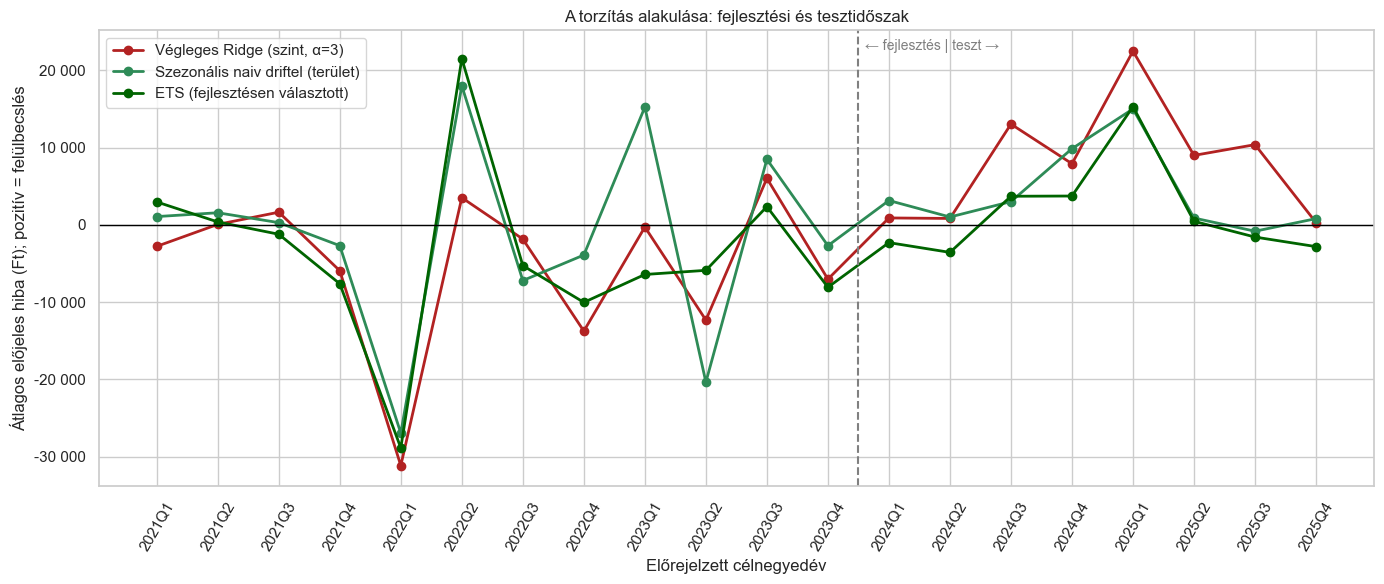

In [14]:
# C.1 NEGYEDÉVENKÉNTI ELŐJELES HIBA, 20 NEGYEDÉV
bias_models = ["Végleges Ridge (szint, α=3)", "Szezonális naiv driftel (terület)", "ETS (fejlesztésen választott)"]
bias_q = pd.DataFrame({m: pd.concat([models[("fejlesztés", m)].groupby("Cél_Dátum")["Hiba"].mean(),
                                     models[("teszt", m)].groupby("Cél_Dátum")["Hiba"].mean()]) for m in bias_models})
bias_q.index = bias_q.index.to_period("Q").astype(str)
display(bias_q.round(0))

# C.2 BIAS A NAPTÁRI CÉLNEGYEDÉV TÍPUSA SZERINT
rows = []
for period in ["fejlesztés", "teszt"]:
    for m in bias_models:
        p = models[(period, m)]
        b = p.groupby(p["Cél_Dátum"].dt.quarter)["Hiba"].mean()
        rows.append({"Időszak": period, "Modell": m, **{f"Q{q}": b.get(q, np.nan) for q in [1, 2, 3, 4]}})
bias_by_quarter_type = pd.DataFrame(rows)
display(bias_by_quarter_type.round(0))

# C.3 A HIBA FELBONTÁSA: torzítás és szórás (teszt)
r = models[("teszt", final_ridge_name)]["Hiba"]
print(f"Teszt: bias = {r.mean():,.0f} Ft; a hiba szórása = {r.std(ddof=0):,.0f} Ft; a bias² az MSE {100 * r.mean() ** 2 / (r ** 2).mean():.0f}%-a")
r = models[("fejlesztés", final_ridge_name)]["Hiba"]
print(f"Fejlesztés: bias = {r.mean():,.0f} Ft; a hiba szórása = {r.std(ddof=0):,.0f} Ft; a bias² az MSE {100 * r.mean() ** 2 / (r ** 2).mean():.0f}%-a")

fig, ax = plt.subplots(figsize=(14, 6))
for m, c in zip(bias_models, ["firebrick", "seagreen", "darkgreen"]):
    ax.plot(bias_q.index, bias_q[m], marker="o", label=m, color=c, linewidth=2)
ax.axhline(0, color="black", linewidth=1)
ax.axvline(len(dev_dates) - 0.5, color="grey", linestyle="--")
ax.text(len(dev_dates) - 0.4, ax.get_ylim()[1] * 0.9, "← fejlesztés | teszt →", fontsize=10, color="grey")
ax.yaxis.set_major_formatter(huf); ax.set_ylabel("Átlagos előjeles hiba (Ft); pozitív = felülbecslés")
ax.set_xlabel("Előrejelzett célnegyedév"); ax.set_title("A torzítás alakulása: fejlesztési és tesztidőszak")
plt.xticks(rotation=60); ax.legend(); plt.tight_layout()
fig.savefig(ML_FIGURES / "bias_alakulasa_fejlesztes_teszt.png", dpi=300, bbox_inches="tight")
plt.show()
bias_q.to_csv(ML_RESULTS / "KSH_rob_bias_negyedevenkent.csv", encoding="utf-8-sig")

**Mit olvass ki belőle?** A Ridge torzítása a fejlesztési időszakban *negatív* (alulbecslés), a tesztben *pozitív*. Ez nem állandó modellhiba, hanem **rezsimváltás**: a rögzített együtthatók a gyorsuló, majd lassuló bérnövekedést késve követik.
Az ETS és a driftes naiv módszer az utolsó megfigyelt növekedéshez igazodik, ezért kisebb a torzításuk.

## D. Utólagos diagnosztika: tanulóablak hossza

A 03. notebook 125–127. cellája már futtatott sliding window kísérletet a fejlesztési időszakon (4, 8, 10 negyedév). Itt kiegészítjük a 12 és 16 negyedéves ablakkal, és **diagnosztikaként** megmutatjuk a tesztet is.
**Ez nem modellválasztás:** a végleges modell marad expanding window. A teszt-oszlop csak a torzítás okának megértését szolgálja, és a dolgozatban „utólagos” jelöléssel szerepelhet.

In [15]:
rows = []
for label, w in [("expanding", None), ("sliding 4", 4), ("sliding 8", 8), ("sliding 10", 10), ("sliding 12", 12), ("sliding 16", 16)]:
    d_ = summarize(walk_forward(df_model, dev_dates, Ridge(alpha=3), label, window=w))
    t_ = summarize(walk_forward(df_model, test_dates, Ridge(alpha=3), label, window=w))
    rows.append({"Tanulóablak": label, "Fejl. MAE": d_["Átlag_MAE"], "Fejl. bias": d_["Bias"],
                 "Teszt MAE (utólagos)": t_["Átlag_MAE"], "Teszt bias (utólagos)": t_["Bias"]})
window_diagnostics = pd.DataFrame(rows)
display(window_diagnostics.round(0))
window_diagnostics.to_csv(ML_RESULTS / "KSH_rob_tanuloablak_diagnosztika.csv", index=False, encoding="utf-8-sig")

,Tanulóablak,Fejl. MAE,Fejl. bias,Teszt MAE (utólagos),Teszt bias (utólagos)
0,expanding,8940.0,-5320.0,10002.0,8101.0
1,sliding 4,10535.0,-7457.0,8230.0,3604.0
2,sliding 8,9396.0,-6000.0,7626.0,2316.0
3,sliding 10,9015.0,-4860.0,8536.0,4802.0
4,sliding 12,8711.0,-4317.0,8945.0,4910.0
5,sliding 16,8793.0,-4921.0,9876.0,6569.0


**Mit olvass ki belőle?** A fejlesztési időszakon egyetlen ablakhossz sem jobb érdemben az expanding windownál, ezért a végleges modell választása indokolt volt. A tesztben a rövidebb ablakok torzítása kisebb, ami összhangban van a rezsimváltás-magyarázattal.
A 03. notebook 93–97. cellája (csak az új bérforráson tanuló modell) hasonlót mutat. **Ezek az eredmények jelenleg nincsenek a dolgozatban**, pedig a torzítás magyarázatához tartoznak.

## E. Forrásváltás és szezonális mintázat a panelben

A KSH-források 2021 és 2022 között váltanak (archív → új, teljes munkáltatói kör). A nyers fájlokból az átfedés előjeles elemzése a 01. notebookba illeszthető (lásd a külön cellát). Itt a **kész panelből** nézzük meg, hol törik meg a mintázat.

Átlagos negyedéves változás (%), 20 terület átlaga


Q,1,2,3,4
Év,,,,
2018,NaN,4.74,-1.10,6.03
2019,1.06,4.39,-0.37,6.38
2020,-1.33,4.91,-1.18,7.39
2021,-1.57,4.44,-1.14,8.06
2022,5.17,0.27,0.49,8.99
2023,1.69,4.53,-1.09,9.61
2024,1.13,4.39,-1.64,7.82
2025,-1.34,4.22,-1.48,7.70


A negyedéves változás területek közötti szórása (%-pont)


Q,1,2,3,4
Év,,,,
2018,NaN,2.05,2.19,2.17
2019,2.03,2.42,1.76,2.10
2020,1.63,2.46,1.43,2.45
2021,2.40,2.20,1.81,1.96
2022,4.26,2.78,1.17,1.96
2023,1.98,2.64,2.21,1.24
2024,1.56,2.37,1.75,1.69
2025,1.29,2.70,2.11,1.57


Átlagos éves változás (%)


Q,1,2,3,4
Év,,,,
2019,10.9,10.6,11.4,11.8
2020,9.1,9.7,8.8,9.8
2021,9.5,9.0,9.1,9.8
2022,17.3,12.5,14.4,15.4
2023,11.6,16.4,14.5,15.2
2024,14.5,14.4,13.8,11.9
2025,9.2,9.0,9.1,9.0


Az éves változás területek közötti szórása (%-pont)


Q,1,2,3,4
Év,,,,
2019,2.00,1.68,1.78,2.26
2020,1.38,2.70,1.69,1.71
2021,1.17,2.07,1.57,1.51
2022,3.61,2.26,1.42,1.82
2023,3.11,1.76,1.08,1.56
2024,1.33,1.82,1.59,1.12
2025,0.99,1.11,0.72,0.94


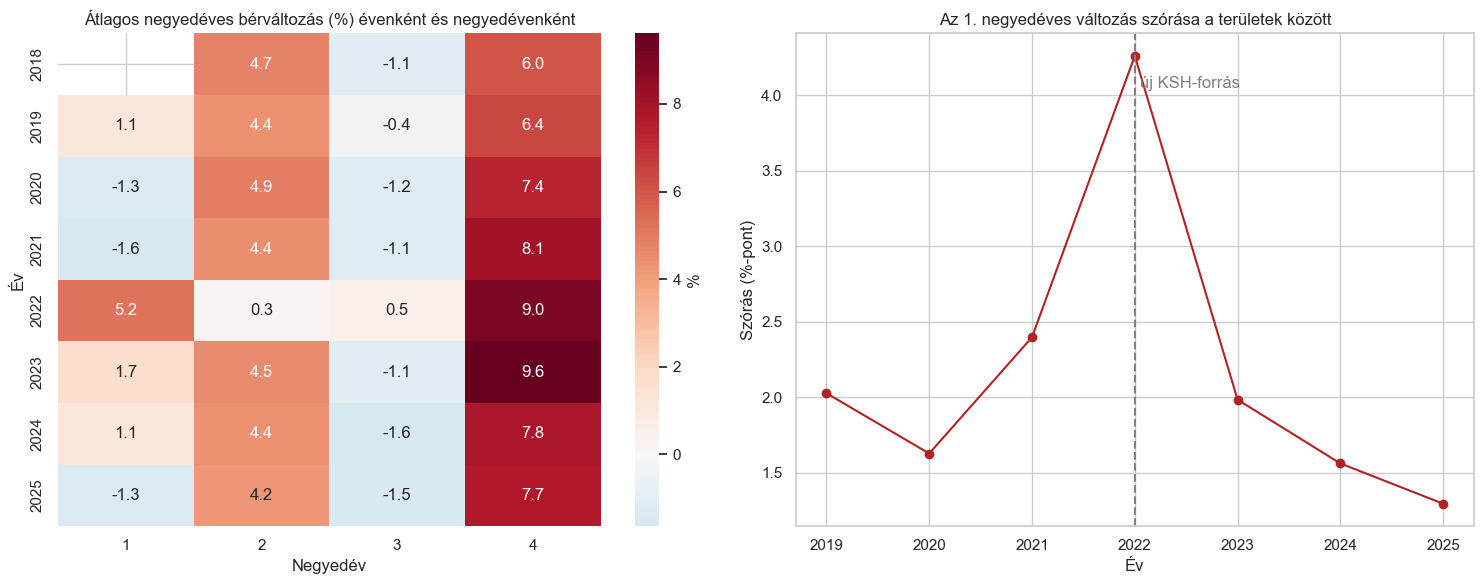

In [16]:
# E.1 NEGYEDÉVES VÁLTOZÁS (QoQ, %) ÉVENKÉNT ÉS NEGYEDÉVENKÉNT
P = df_panel.copy()
P["Év"], P["Q"] = P["Dátum"].dt.year, P["Dátum"].dt.quarter
P["qoq"], P["yoy"] = P["Bér_Növekedés_QoQ"] * 100, P["Bér_Növekedés_YoY"] * 100
qoq_table = P.pivot_table(index="Év", columns="Q", values="qoq", aggfunc="mean")
qoq_sd = P.pivot_table(index="Év", columns="Q", values="qoq", aggfunc="std")
yoy_table = P.pivot_table(index="Év", columns="Q", values="yoy", aggfunc="mean")
yoy_sd = P.pivot_table(index="Év", columns="Q", values="yoy", aggfunc="std")
print("Átlagos negyedéves változás (%), 20 terület átlaga"); display(qoq_table.round(2))
print("A negyedéves változás területek közötti szórása (%-pont)"); display(qoq_sd.round(2))
print("Átlagos éves változás (%)"); display(yoy_table.round(1))
print("Az éves változás területek közötti szórása (%-pont)"); display(yoy_sd.round(2))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.heatmap(qoq_table, annot=True, fmt=".1f", cmap="RdBu_r", center=0, ax=axes[0], cbar_kws={"label": "%"})
axes[0].set_title("Átlagos negyedéves bérváltozás (%) évenként és negyedévenként")
axes[0].set_xlabel("Negyedév"); axes[0].set_ylabel("Év")
q1 = qoq_sd[1].dropna()
axes[1].plot(q1.index, q1.values, marker="o", color="firebrick")
axes[1].set_title("Az 1. negyedéves változás szórása a területek között")
axes[1].set_xlabel("Év"); axes[1].set_ylabel("Szórás (%-pont)")
axes[1].axvline(2022, color="grey", linestyle="--"); axes[1].text(2022.05, q1.max() * 0.95, "új KSH-forrás", color="grey")
plt.tight_layout()
fig.savefig(FIGURES / "forrasvaltas_szezonalis_mintazat.png", dpi=300, bbox_inches="tight")
plt.show()
qoq_table.to_csv(ML_RESULTS / "KSH_rob_qoq_evenkent_negyedevenkent.csv", encoding="utf-8-sig")

**Mit olvass ki belőle?** 2022-ben a megszokott szezonális mintázat megtörik: az 1. negyedéves változás átlaga +5,2% (a többi évben −1,6 és +1,7% között), a területek közötti szórása is megduplázódik, a 2. negyedéves változás pedig csak +0,3% (egyébként ~4,4%).
Ez *összhangban van* a forrásváltással, de **nem bizonyítja** azt, mert 2022 elején valódi béremelések is voltak (minimálbér, közszféra). A szétválasztáshoz kell az átfedő adatok előjeles összehasonlítása (01. notebook).

## F. A klaszterezés robusztussága

A 4.3 szerint a Ward- és a KMeans-besorolás egyezése (ARI = 1) erősíti a felosztást. Mivel k = 2 esetén szinte bármely módszer ugyanazt a vágást adja, érdemes más típusú ellenőrzést is végezni: (i) a növekedési változó forrásváltástól mentes változata, (ii) Budapest nélkül, (iii) k = 3.

In [ ]:
# F.1 PROFIL ÉS A FORRÁSON BELÜLI NÖVEKEDÉS
ann = P.groupby([AREA, "Év"])["Bruttó_átlagkereset_HUF"].mean().unstack("Év")
profile = pd.DataFrame({
    "Átlagbér_2025": ann[2025],
    "Növekedés_eredeti_%": ((ann[2025] / ann[2018]) ** (1 / 7) - 1) * 100,                                    # 2018 archív → 2025 új forrás
    "Növekedés_forráson_belül_%": (((ann[2021] / ann[2018]) * (ann[2025] / ann[2022])) ** (1 / 6) - 1) * 100,  # a 2021→2022 lépés kihagyva
    "Munkanélküliség": P.groupby(AREA)["Munkanélküliségi_ráta_%"].mean()})

def ward_labels(frame, columns, k):
    Z = StandardScaler().fit_transform(frame[columns])
    return pd.Series(AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(Z), index=frame.index), Z

orig_cols = ["Átlagbér_2025", "Növekedés_eredeti_%", "Munkanélküliség"]
alt_cols = ["Átlagbér_2025", "Növekedés_forráson_belül_%", "Munkanélküliség"]
base_labels, Zb = ward_labels(profile, orig_cols, 2)

rows = []
def silhouettes(frame, columns, label):
    out = {"Változat": label}
    Z = StandardScaler().fit_transform(frame[columns])
    for k in range(2, 7):
        lab = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(Z)
        out[f"sziluett k={k}"] = silhouette_score(Z, lab)
    return out
rows.append(silhouettes(profile, orig_cols, "Eredeti (dolgozat)"))
rows.append(silhouettes(profile, alt_cols, "Növekedés forráson belül"))
rows.append(silhouettes(profile.drop(index="Budapest"), orig_cols, "Budapest nélkül (19 terület)"))
cluster_robustness = pd.DataFrame(rows)
display(cluster_robustness.round(3))

# F.2 BESOROLÁS-ÖSSZEHASONLÍTÁS (címkéktől független: ARI, és mely területek mozdulnak)
alt_labels, _ = ward_labels(profile, alt_cols, 2)
if (alt_labels == base_labels).mean() < 0.5:
    alt_labels = 1 - alt_labels
nb_labels, _ = ward_labels(profile.drop(index="Budapest"), orig_cols, 2)
print("ARI: eredeti vs. forráson belüli növekedés (k=2):", round(adjusted_rand_score(base_labels, alt_labels), 3))
print("Területek, amelyek besorolása megváltozik:", list(profile.index[base_labels != alt_labels]))
print("ARI: eredeti vs. Budapest nélkül (19 terület):", round(adjusted_rand_score(base_labels.drop(index="Budapest"), nb_labels), 3))
print("Az éves növekedés két változata közti Pearson / Spearman:",
      round(profile[["Növekedés_eredeti_%", "Növekedés_forráson_belül_%"]].corr().iloc[0, 1], 3),
      round(stats.spearmanr(profile["Növekedés_eredeti_%"], profile["Növekedés_forráson_belül_%"])[0], 3))

# F.3 k=3 ÉS AZ EGYTAGÚ KLASZTER
labels3, Z3 = ward_labels(profile, orig_cols, 3)
for c in sorted(labels3.unique()):
    print(f"k=3, klaszter {c} ({(labels3 == c).sum()} terület):", ", ".join(labels3.index[labels3 == c]))
km2 = KMeans(2, n_init=50, random_state=42).fit_predict(Zb)
print("ARI Ward vs. KMeans, k=2:", round(adjusted_rand_score(base_labels, km2), 3))
cluster_robustness.to_csv(PROCESSED / "KSH_rob_klaszter_robusztussag.csv", index=False, encoding="utf-8-sig")

,Változat,sziluett k=2,sziluett k=3,sziluett k=4,sziluett k=5,sziluett k=6
0,Eredeti (dolgozat),0.412,0.396,0.355,0.338,0.224
1,Növekedés forráson belül,0.323,0.306,0.322,0.335,0.345
2,Budapest nélkül (19 terület),0.426,0.390,0.313,0.318,0.343


ARI: eredeti vs. forráson belüli növekedés (k=2): 0.62
Területek, amelyek besorolása megváltozik: ['Bács-Kiskun', 'Tolna']
ARI: eredeti vs. Budapest nélkül (19 terület): 1.0
Az éves növekedés két változata közti Pearson / Spearman: 0.769 0.797
k=3, klaszter 0 (9 terület): Baranya, Borsod-Abaúj-Zemplén, Békés, Hajdú-Bihar, Jász-Nagykun-Szolnok, Nógrád, Somogy, Szabolcs-Szatmár-Bereg, Zala
k=3, klaszter 1 (10 terület): Bács-Kiskun, Csongrád-Csanád, Fejér, Győr-Moson-Sopron, Heves, Komárom-Esztergom, Pest, Tolna, Vas, Veszprém
k=3, klaszter 2 (1 terület): Budapest
ARI Ward vs. KMeans, k=2: 1.0


**Mit olvass ki belőle?** A k = 2 felosztás Budapest nélkül is ugyanaz (ARI = 1), a forrásváltástól mentes növekedési változóval pedig csak a két határeset, Bács-Kiskun és Tolna sorolódik át. A besorolás tehát lényegében stabil, de a sziluettérték a gyengébb tartományban marad, és k = 3-nál Budapest egyedül alkot klasztert.
A dolgozatban „stabil, de gyenge szerkezet” fogalmazás indokolt.

## G. A területi együttmozgás robusztussága

A 4.2.6 szerint Budapest éves bérváltozása Zalával korrelál legerősebben (0,905), Pesttel gyengén (0,515), ezért „a hasonlóság nem szomszédsági kérdés”. Az éves növekedési ráták átfedő ablakokból állnak, és 2022 mindegyik terület mozgását közösen torzítja, ezért négy változatot hasonlítunk össze: eredeti, a keresztmetszeti átlagtól való eltérés, első differencia és 2022 nélkül.

,eredeti,átlagtól eltérés,első differencia,2022 nélkül,2022–2023 nélkül
Területi egység neve,,,,,
Zala,0.90,0.49,0.94,0.90,0.91
Baranya,0.86,0.47,0.84,0.82,0.79
Bács-Kiskun,0.86,0.13,0.79,0.79,0.79
Jász-Nagykun-Szolnok,0.85,0.23,0.84,0.85,0.80
Szabolcs-Szatmár-Bereg,0.85,0.31,0.87,0.76,0.67
Hajdú-Bihar,0.84,0.19,0.90,0.81,0.74
Békés,0.84,0.13,0.90,0.80,0.67
Csongrád-Csanád,0.84,0.21,0.90,0.75,0.63
Somogy,0.82,-0.24,0.83,0.78,0.68


,Változat,n negyedév,Átlagos páronkénti r,Budapest–Pest,Budapest–Zala,Rangkorreláció az eredeti Budapest-sorral
0,eredeti,28,0.70,0.52,0.90,1.00
1,átlagtól eltérés,28,-0.05,-0.29,0.49,0.77
2,első differencia,27,0.60,0.28,0.94,0.84
3,2022 nélkül,24,0.70,0.72,0.90,0.88
4,2022–2023 nélkül,20,0.60,0.83,0.91,0.61


eredeti            legerősebb három pár: [('Csongrád-Csa', 'Nógrád', 0.96), ('Csongrád-Csa', 'Hajdú-Bihar', 0.95), ('Nógrád', 'Szabolcs-Sza', 0.95)]
átlagtól eltérés   legerősebb három pár: [('Nógrád', 'Szabolcs-Sza', 0.84), ('Komárom-Eszt', 'Pest', 0.8), ('Csongrád-Csa', 'Nógrád', 0.78)]
első differencia   legerősebb három pár: [('Békés', 'Nógrád', 0.95), ('Csongrád-Csa', 'Nógrád', 0.94), ('Nógrád', 'Somogy', 0.94)]
2022 nélkül        legerősebb három pár: [('Csongrád-Csa', 'Hajdú-Bihar', 0.96), ('Békés', 'Somogy', 0.95), ('Hajdú-Bihar', 'Szabolcs-Sza', 0.94)]


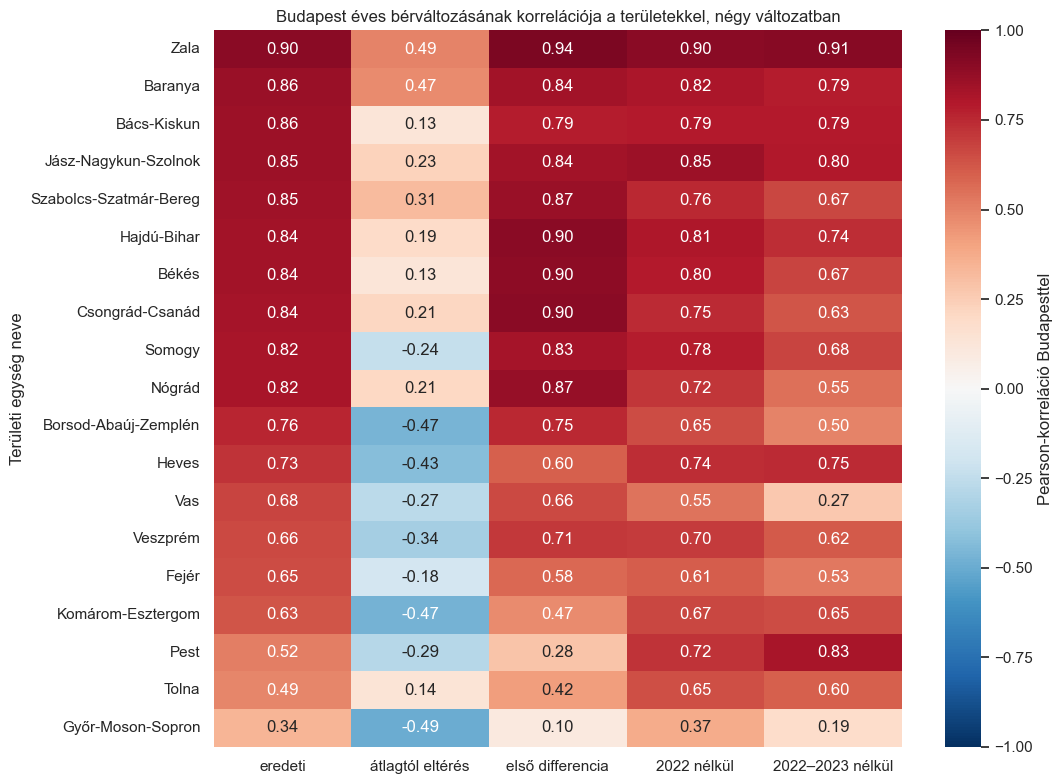

In [18]:
Y = P.pivot(index="Dátum", columns=AREA, values="yoy").dropna()
assert Y.shape == (28, 20)
variants = {"eredeti": Y,
            "átlagtól eltérés": Y.sub(Y.mean(axis=1), axis=0),
            "első differencia": Y.diff().dropna(),
            "2022 nélkül": Y[Y.index.year != 2022],
            "2022–2023 nélkül": Y[~Y.index.year.isin([2022, 2023])]}
corr = {k: v.corr() for k, v in variants.items()}

bp = pd.DataFrame({k: c.loc["Budapest"].drop("Budapest") for k, c in corr.items()})
display(bp.sort_values("eredeti", ascending=False).round(2))

summary_rows = []
for k, c in corr.items():
    row = c.loc["Budapest"].drop("Budapest")
    off = c.values[np.triu_indices(20, 1)]
    summary_rows.append({"Változat": k, "n negyedév": len(variants[k]), "Átlagos páronkénti r": off.mean(),
                         "Budapest–Pest": row["Pest"], "Budapest–Zala": row["Zala"],
                         "Rangkorreláció az eredeti Budapest-sorral": stats.spearmanr(bp["eredeti"], row)[0]})
corr_robustness = pd.DataFrame(summary_rows)
display(corr_robustness.round(2))
for k in ["eredeti", "átlagtól eltérés", "első differencia", "2022 nélkül"]:
    upper = corr[k].where(np.triu(np.ones((20, 20)), 1).astype(bool)).stack().sort_values(ascending=False)
    print(f"{k:18s} legerősebb három pár:", [(a[:12], b[:12], round(v, 2)) for (a, b), v in upper.head(3).items()])

fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(bp.sort_values("eredeti", ascending=False), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax,
            cbar_kws={"label": "Pearson-korreláció Budapesttel"})
ax.set_title("Budapest éves bérváltozásának korrelációja a területekkel, négy változatban")
plt.tight_layout()
fig.savefig(FIGURES / "budapest_korrelacio_robusztussag.png", dpi=300, bbox_inches="tight")
plt.show()
corr_robustness.to_csv(ML_RESULTS / "KSH_rob_korrelacio_robusztussag.csv", index=False, encoding="utf-8-sig")
bp.to_csv(ML_RESULTS / "KSH_rob_budapest_korrelaciok.csv", encoding="utf-8-sig")

**Mit olvass ki belőle?** A Budapest–Pest korreláció 2022 nélkül 0,72, 2022–2023 nélkül 0,83 (az eredeti 0,52). A „Zala közelebb van Budapesthez, mint Pest” kép tehát nagyrészt egyetlen év (2022) hatása.
A keresztmetszeti átlagtól való eltérés mutatja a *relatív* együttmozgást (a páronkénti átlag szükségszerűen ≈ −0,05). A dolgozatban a 4.2.6 földrajzra vonatkozó megállapítását ennek megfelelően puhítani kell.

In [ ]:
# ÖSSZEFOGLALÓ A DOLGOZATHOZ
key = {
    "Ridge (szint) fejlesztési MAE": reference_summary.query("Modell == @final_ridge_name and Időszak == 'fejlesztés'")["Átlag_MAE"].iloc[0],
    "Ridge (szint) teszt MAE": reference_summary.query("Modell == @final_ridge_name and Időszak == 'teszt'")["Átlag_MAE"].iloc[0],
    "Ridge (szint) teszt bias": reference_summary.query("Modell == @final_ridge_name and Időszak == 'teszt'")["Bias"].iloc[0],
    "Ridge (szint) fejlesztési bias": reference_summary.query("Modell == @final_ridge_name and Időszak == 'fejlesztés'")["Bias"].iloc[0],
    "Szez. naiv driftel (terület) teszt MAE": reference_summary.query("Modell == 'Szezonális naiv driftel (terület)' and Időszak == 'teszt'")["Átlag_MAE"].iloc[0],
    "ETS teszt MAE": reference_summary.query("Modell == 'ETS (fejlesztésen választott)' and Időszak == 'teszt'")["Átlag_MAE"].iloc[0],
    "Kiválasztott ETS (fejlesztésen)": ets_choice,
}
summary_table = pd.Series(key, name="Érték").to_frame()
display(summary_table)
summary_table.to_csv(ML_RESULTS / "KSH_rob_osszefoglalo.csv", encoding="utf-8-sig")
print("A robusztussági kiegészítések lefutottak, az eredmények a results/machine_learning és a figures mappákban vannak.")

,Érték
Ridge (szint) fejlesztési MAE,8939.824339
Ridge (szint) teszt MAE,10001.612931
Ridge (szint) teszt bias,8100.987466
Ridge (szint) fejlesztési bias,-5320.49714
Szez. naiv driftel (terület) teszt MAE,6434.462953
ETS teszt MAE,5913.614527
Kiválasztott ETS (fejlesztésen),ETS mul. szezon + damped trend


A robusztussági kiegészítések lefutottak, az eredmények a results/machine_learning és a figures mappákban vannak.
